In [3]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
import calendar
from google.colab import drive
drive.mount('/content/drive')
sns.set_theme(style='whitegrid')

D = '/content/drive/MyDrive/MinneMUDAC 26 for BU/'
M = ['HouseholdsReg','PoundsReg','ChildrenReg','AdultsReg','SeniorsReg']   # the 5 targets

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
fs   = pd.read_excel(D + 'By Organizers/Data/org_FSStats.xlsx')
orgs = pd.read_excel(D + 'By Organizers/Data/Organization.xlsx').drop_duplicates('__ID')
tpl = pd.read_excel(D + 'By Organizers/PredictionFile/Grad_Team_XX_TFG_MinneMUDAC.xlsx')
fs.shape, orgs.shape, tpl.shape        # (28287, 58) (1202, 68) (87, 6)

((28287, 58), (1202, 68), (87, 6))

In [5]:
empty = fs.columns[fs.notna().sum() == 0]
fs = fs.drop(columns=empty)
fs = fs.drop(columns=['SuperShelf'])          # broken, populated on 1 site
print(len(empty), fs.shape)                   # 24 (28287, 33)

24 (28287, 33)


In [6]:
# _Year/_Month disagree with DateForSearch on 26 rows (month 0 = Dec of prior year,
# month 15 = March of next). DateForSearch is populated on all 28,287 rows.
fs = fs.drop(columns=['_Year','_Month'])
fs.DateForSearch = pd.to_datetime(fs.DateForSearch)
print(fs.shape, fs.DateForSearch.min().date(), fs.DateForSearch.max().date())
# (28287, 31) 2022-01-01 2026-07-01

(28287, 31) 2022-01-01 2026-07-01


In [7]:
q7 = fs[fs.DateForSearch >= '2022-01-01'].copy()
assert (q7.DateForSearch >= '2026-08-01').sum() == 0, 'AUGUST DATA PRESENT — STOP'
print(len(q7), q7.groupby(q7.DateForSearch.dt.year).size().to_dict())
# 28287 {2022: 5984, 2023: 6543, 2024: 6229, 2025: 6023, 2026: 3508}

28287 {2022: 5984, 2023: 6543, 2024: 6229, 2025: 6023, 2026: 3508}


In [8]:
bad  = q7.HouseholdsReg > q7.IndividualsReg
wase = (q7._id_site == 1197.0) & (q7.DateForSearch == '2023-07-01')
q7.loc[wase, 'HouseholdsReg'] = 311           # 273,385 vs 646 individuals; neighbours are 285/338

def _ratio(df, key):
    g = df.groupby(key)[['IndividualsReg','HouseholdsReg']].sum()
    return (g.IndividualsReg / g.HouseholdsReg).where(lambda s: s >= 1.5)

cl = q7[~bad]
r  = (q7._id_site.map(_ratio(cl, '_id_site'))
        .fillna(q7.County.map(_ratio(cl, 'County')))
        .fillna(cl.IndividualsReg.sum() / cl.HouseholdsReg.sum()))
fixable = bad & (q7.IndividualsReg > 0) & ~wase
q7.loc[fixable, 'HouseholdsReg'] = (q7.loc[fixable,'IndividualsReg'] / r[fixable]).round()
print(bad.sum(), fixable.sum(), (bad & (q7.IndividualsReg == 0)).sum())   # 153 148 4

153 148 4


In [9]:
FIX = {'Hennepin-Minneapolis':'Hennepin','Hennepin-Suburbs':'Hennepin',
       'Ramsey-Saint Paul':'Ramsey','Ramsey-Suburbs':'Ramsey',
       'Lac Qui Parle':'Lac qui Parle','Saint Louis':'St. Louis',
       'Lake of the Woods':'Lake Of The Woods'}

q7['county'] = (q7.County.replace(FIX)
                  .fillna(q7._id_site.map({15362.0:'Rice', 15363.0:'Rice', 15218.0:'Cass'})))
q7 = q7[q7.county.notna()].copy()             # drops 90 unassignable rows, 0.88% of pounds
q7['ym'] = q7.DateForSearch.dt.to_period('M')

# blank age splits are true zeros: C+A+S = Individuals on all 26,259 complete rows
for c in ['ChildrenReg','AdultsReg','SeniorsReg']:
    q7[c] = q7[c].fillna(0)

print(sorted(set(q7.county) - set(tpl.County)))   # []

[]


In [10]:
panel = q7.groupby(['county','ym'])[M].sum().reset_index()
full  = pd.MultiIndex.from_product(
    [sorted(tpl.County), pd.period_range('2022-01','2026-07', freq='M')],
    names=['county','ym'])
panel = panel.set_index(['county','ym']).reindex(full).fillna(0.0).reset_index()
panel['ts'] = panel.ym.dt.to_timestamp()

site = q7.groupby(['_id_site','county','ym'])[M].sum().reset_index()
orgs['InactiveDate'] = pd.to_datetime(orgs.InactiveDate, errors='coerce')
site['inactive_from'] = site._id_site.map(orgs.set_index('__ID').InactiveDate)

print(panel.shape, site.shape)                # (4785, 8) (28116, 9)
print(panel.groupby('ts').HouseholdsReg.sum().loc['2023-07'])   # 211038.0  <- D3 working

(4785, 8) (28116, 9)
ts
2023-07-01    211077.0
Name: HouseholdsReg, dtype: float64


In [11]:
s = panel.groupby('ts')[M].sum()
aug = pd.DataFrame({
    'Jun': s.HouseholdsReg[s.index.month == 6].values[:5],
    'Jul': s.HouseholdsReg[s.index.month == 7].values[:5],
    'Aug': list(s.HouseholdsReg[s.index.month == 8].values) + [np.nan],
}, index=[2022, 2023, 2024, 2025, 2026])
aug['Aug/Jul'] = (aug.Aug / aug.Jul).round(3)   # 1.110 1.124 1.025 0.927 nan

def weekdays(y, m):
    n = calendar.monthrange(y, m)[1]
    return int((pd.date_range(f'{y}-{m:02d}-01', periods=n, freq='D').dayofweek < 5).sum())

aug['Aug_weekdays'] = [weekdays(y, 8) for y in aug.index]   # 23 23 22 21 21
aug

,Jun,Jul,Aug,Aug/Jul,Aug_weekdays
2022,176791.0,171423.0,190292.0,1.110,23
2023,217532.0,211077.0,237226.0,1.124,23
2024,228982.0,235285.0,241269.0,1.025,22
2025,236961.0,258482.0,239540.0,0.927,21
2026,238406.0,238043.0,NaN,NaN,21


In [12]:
def forecast(hist_wide, how, win=3):
    """hist_wide: months x counties, already cut off before the target month."""
    if how == 'last':      return hist_wide.iloc[-1]
    if how == 'mean':      return hist_wide.iloc[-win:].mean()
    if how == 'prior_aug':
        a = hist_wide[hist_wide.index.month == 8]
        return a.iloc[-1] if len(a) else hist_wide.iloc[-1]
    raise ValueError(how)

def rmse(f, a): return float(np.sqrt(((f - a) ** 2).mean()))

IDX  = sorted(tpl.County)
rows = []
for yr in [2023, 2024, 2025]:
    tgt = pd.Period(f'{yr}-08', 'M')
    for v in M:
        wide = panel.pivot(index='ym', columns='county', values=v).sort_index()
        hist = wide[wide.index < tgt]
        act  = wide.loc[tgt].reindex(IDX).fillna(0)
        for lab, how, win in [('carry July','last',0), ('mean2','mean',2),
                              ('mean3','mean',3), ('mean4','mean',4),
                              ('mean6','mean',6), ('mean12','mean',12),
                              ('prior August','prior_aug',0)]:
            f = forecast(hist, how, win).reindex(IDX).fillna(0)
            rows.append(dict(year=yr, metric=v, method=lab, rmse=rmse(f, act)))

res = pd.DataFrame(rows)
res.pivot_table(index='method', columns='metric', values='rmse').round(1)

metric,AdultsReg,ChildrenReg,HouseholdsReg,PoundsReg,SeniorsReg
method,,,,,
carry July,1625.5,1176.5,968.5,57098.2,278.1
mean12,2037.6,1855.2,1232.0,62497.7,348.9
mean2,1307.0,897.5,712.9,52792.6,273.5
mean3,1248.6,991.6,782.3,52253.1,304.7
mean4,1406.3,1184.7,903.6,54560.8,314.3
mean6,1624.7,1421.2,1040.0,60103.1,333.1
prior August,2826.6,2103.7,1806.1,77413.1,648.4


In [13]:
best = (res.groupby(['metric','method']).rmse.mean()
           .reset_index().sort_values(['metric','rmse'])
           .groupby('metric').first())
best   # mean3 won 4 of 5 on my run; mean2/mean4 untested until you execute cell 11

,method,rmse
metric,,
AdultsReg,mean3,1248.639857
ChildrenReg,mean2,897.456663
HouseholdsReg,mean2,712.850329
PoundsReg,mean3,52253.078920
SeniorsReg,mean2,273.489086


In [15]:
WIN = 3                                        # set from cell 12
hist_end = pd.Period('2026-07', 'M')
out = tpl[['County']].copy()

for col, v in [('Visits','HouseholdsReg'), ('Pounds','PoundsReg'),
               ('Children','ChildrenReg'), ('Adults','AdultsReg'), ('Seniors','SeniorsReg')]:
    wide = panel.pivot(index='ym', columns='county', values=v).sort_index()
    pred = wide.loc[:hist_end].iloc[-WIN:].mean()
    out[col] = out.County.map(pred).round(0)

print(out.shape, out.notna().all().all(), list(out.columns) == list(tpl.columns))

# statewide totals, against the last few actual months as a sanity check
print('\npredicted Aug 2026 statewide:')
print(out[['Visits','Pounds','Children','Adults','Seniors']].sum().apply(lambda x: f'{x:,.0f}'))
print('\nactual recent months:')
print(panel.groupby('ym')[M].sum().tail(4).round(0).to_string())

print('\ntop 10 counties:')
print(out.nlargest(10, 'Visits').to_string(index=False))
print('\nWilkin + Lake Of The Woods:')
print(out[out.County.isin(['Wilkin','Lake Of The Woods'])].to_string(index=False))

(87, 6) True True

predicted Aug 2026 statewide:
Visits         235,000
Pounds      12,263,170
Children       258,020
Adults         386,891
Seniors         85,216
dtype: object

actual recent months:
         HouseholdsReg   PoundsReg  ChildrenReg  AdultsReg  SeniorsReg
ym                                                                    
2026-04       256038.0  13074244.0     277775.0   433316.0     90419.0
2026-05       228555.0  11536292.0     254791.0   371641.0     83753.0
2026-06       238406.0  12253807.0     259699.0   394713.0     86321.0
2026-07       238043.0  12999405.0     259559.0   394311.0     85574.0

top 10 counties:
    County  Visits    Pounds  Children   Adults  Seniors
  Hennepin 70454.0 3830498.0   79842.0 117224.0  20304.0
    Ramsey 22457.0 1093130.0   29965.0  40933.0   7045.0
Washington 22296.0  744138.0   25819.0  39730.0  10282.0
     Anoka 16232.0  759033.0   27535.0  32469.0   5578.0
    Dakota 14264.0  876135.0   15221.0  22435.0   5769.0
   Olmsted 10

Text(0.5, 1.02, 'Forecast error on three hold-out Augusts')

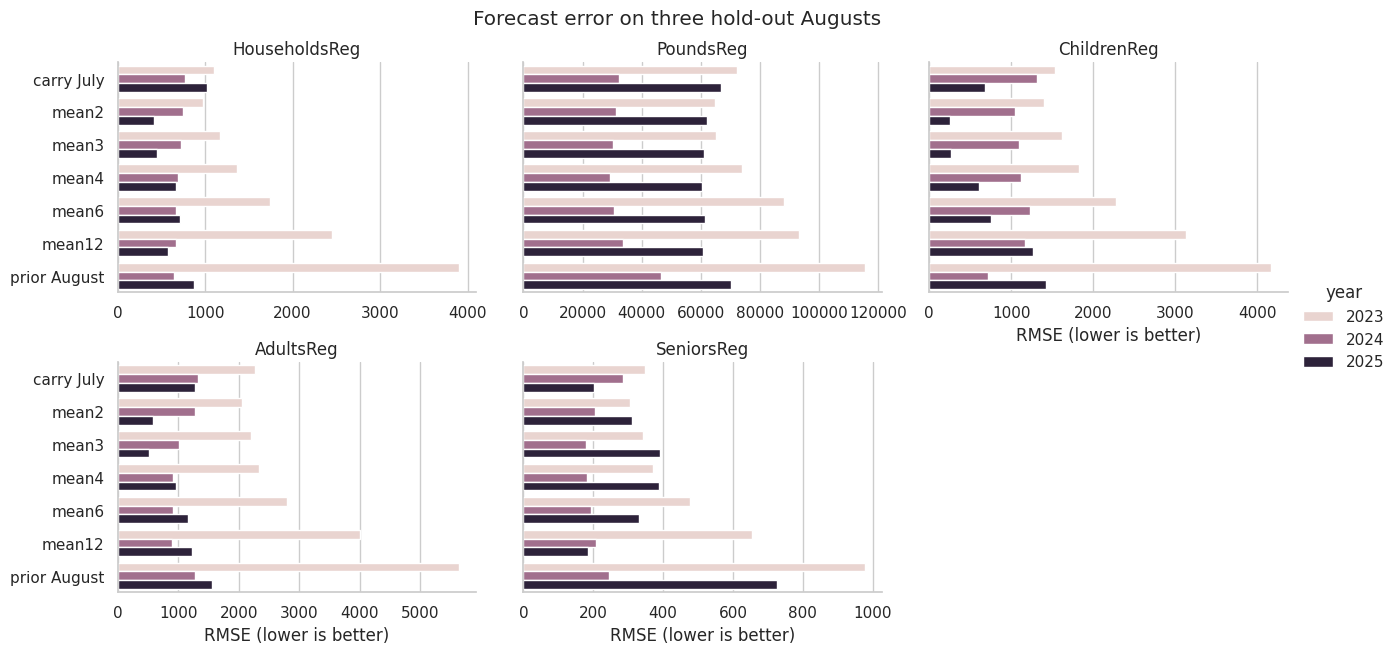

In [16]:
g = sns.catplot(data=res, x='rmse', y='method', col='metric', hue='year',
                kind='bar', col_wrap=3, sharex=False, height=3.2, aspect=1.4,
                order=['carry July','mean2','mean3','mean4','mean6','mean12','prior August'])
g.set_titles('{col_name}')
g.set_axis_labels('RMSE (lower is better)', '')
g.fig.suptitle('Forecast error on three hold-out Augusts', y=1.02)

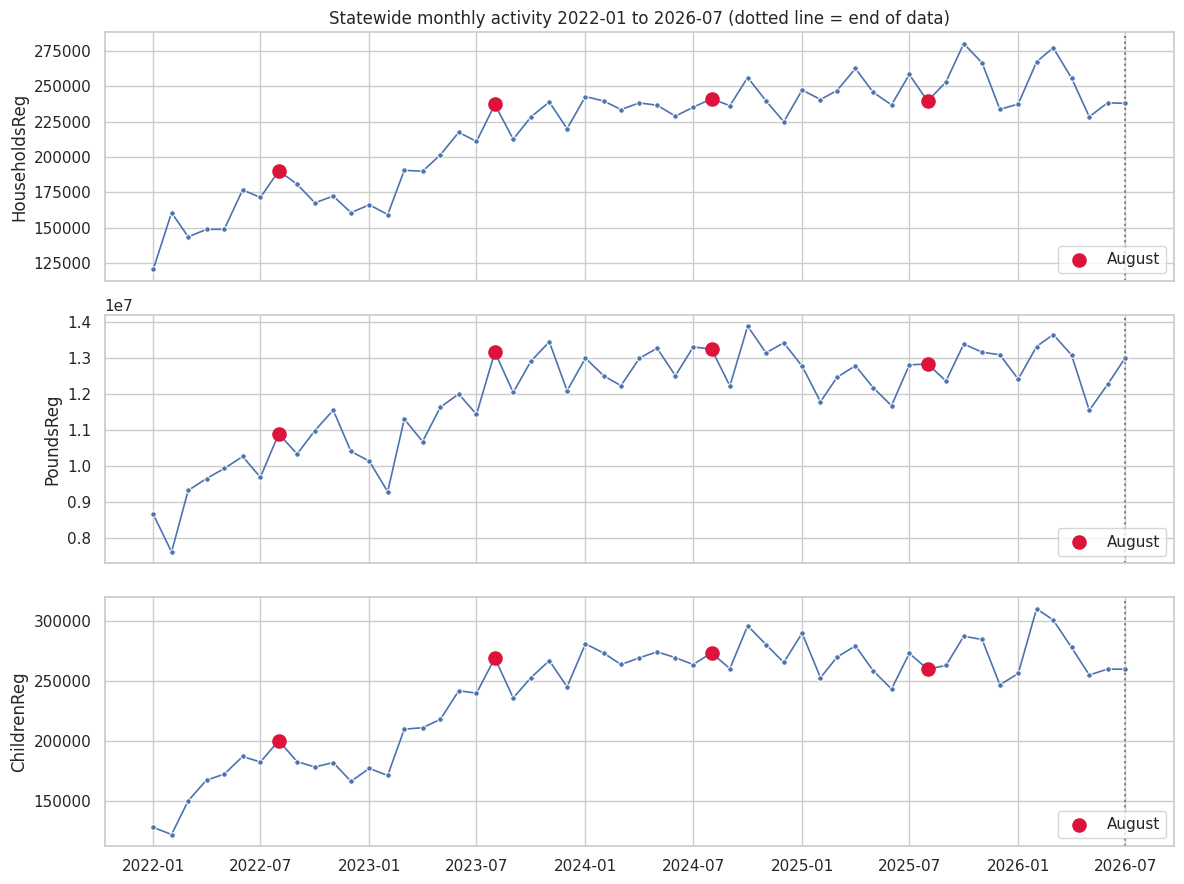

In [17]:
s = panel.groupby('ts')[M].sum()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, v in zip(axes, ['HouseholdsReg','PoundsReg','ChildrenReg']):
    sns.lineplot(x=s.index, y=s[v], ax=ax, marker='o', ms=4, lw=1.2)
    a = s[s.index.month == 8]
    ax.scatter(a.index, a[v], color='crimson', s=90, zorder=5, label='August')
    ax.axvline(pd.Timestamp('2026-07-01'), ls=':', color='grey')
    ax.set(ylabel=v, xlabel=''); ax.legend(loc='lower right')
axes[0].set_title('Statewide monthly activity 2022-01 to 2026-07 (dotted line = end of data)')
plt.tight_layout()

[None,
 None,
 (31.200000000000003, 100657.59999999999),
 (31.200000000000003, 100657.59999999999),
 Text(0.5, 0, 'Actual visits, Aug 2025'),
 Text(0, 0.5, 'Predicted (3-month mean)'),
 Text(0.5, 1.0, 'Dashed line = perfect prediction')]

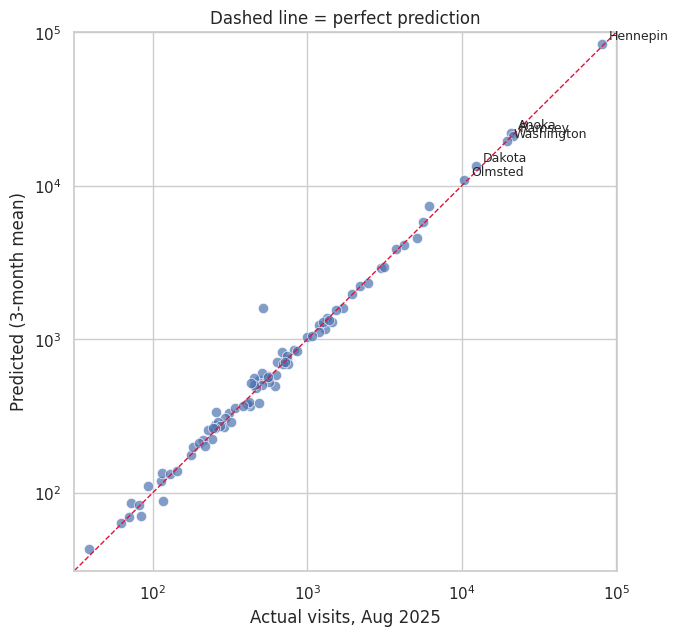

In [18]:
h = panel.pivot(index='ym', columns='county', values='HouseholdsReg').sort_index()
cmp = pd.DataFrame({'predicted': h.loc['2025-05':'2025-07'].mean(),
                    'actual':    h.loc['2025-08']}).reset_index()
cmp = cmp[cmp.actual > 0]

fig, ax = plt.subplots(figsize=(7,7))
sns.scatterplot(data=cmp, x='actual', y='predicted', s=55, alpha=.7, ax=ax)
lim = [cmp[['actual','predicted']].min().min()*0.8, cmp[['actual','predicted']].max().max()*1.2]
ax.plot(lim, lim, ls='--', color='crimson', lw=1)
for _, r in cmp.nlargest(6, 'actual').iterrows():
    ax.annotate(r.county, (r.actual, r.predicted), xytext=(5,3),
                textcoords='offset points', fontsize=9)
ax.set(xscale='log', yscale='log', xlim=lim, ylim=lim,
       xlabel='Actual visits, Aug 2025', ylabel='Predicted (3-month mean)',
       title='Dashed line = perfect prediction')

top 3 counties = 80% of all error


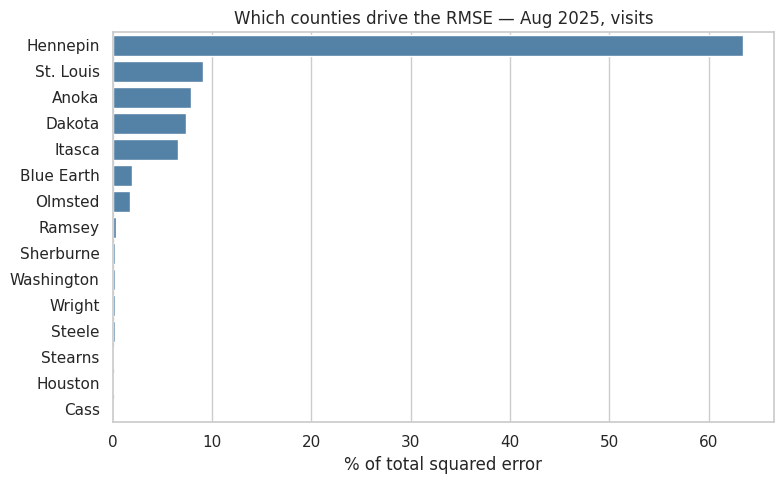

In [19]:
cmp['sq_err'] = (cmp.predicted - cmp.actual)**2
cmp['share']  = cmp.sq_err / cmp.sq_err.sum() * 100

fig, ax = plt.subplots(figsize=(8,5))
sns.barplot(data=cmp.nlargest(15,'share'), x='share', y='county',
            color='steelblue', ax=ax)
ax.set(xlabel='% of total squared error', ylabel='',
       title='Which counties drive the RMSE — Aug 2025, visits')
plt.tight_layout()
print(f"top 3 counties = {cmp.nlargest(3,'share').share.sum():.0f}% of all error")

[None,
 None,
 Text(0.5, 0, 'Actual July 2026 visits'),
 Text(0, 0.5, 'Predicted Aug 2026 visits'),
 Text(0.5, 1.0, 'Sanity check — should hug the line')]

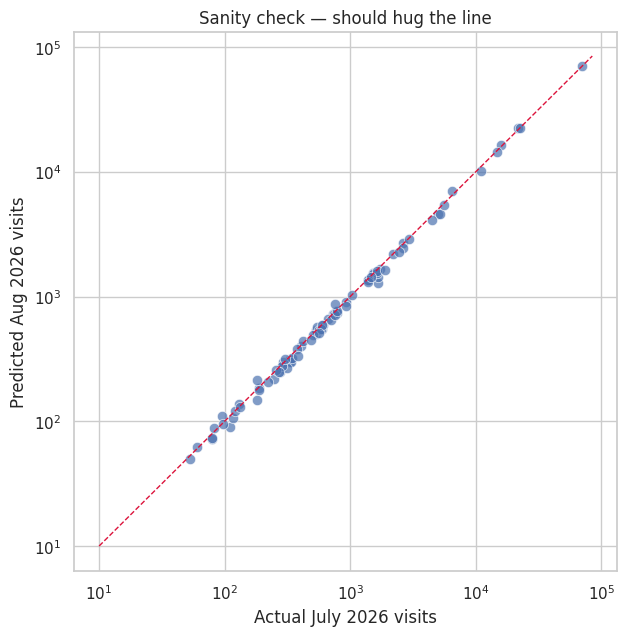

In [20]:
chk = out.merge(panel[panel.ym == pd.Period('2026-07','M')][['county','HouseholdsReg']],
                left_on='County', right_on='county')
fig, ax = plt.subplots(figsize=(7,7))
sns.scatterplot(data=chk[chk.HouseholdsReg > 0], x='HouseholdsReg', y='Visits',
                s=55, alpha=.7, ax=ax)
lim = [10, chk[['HouseholdsReg','Visits']].max().max()*1.2]
ax.plot(lim, lim, ls='--', color='crimson', lw=1)
ax.set(xscale='log', yscale='log', xlabel='Actual July 2026 visits',
       ylabel='Predicted Aug 2026 visits', title='Sanity check — should hug the line')

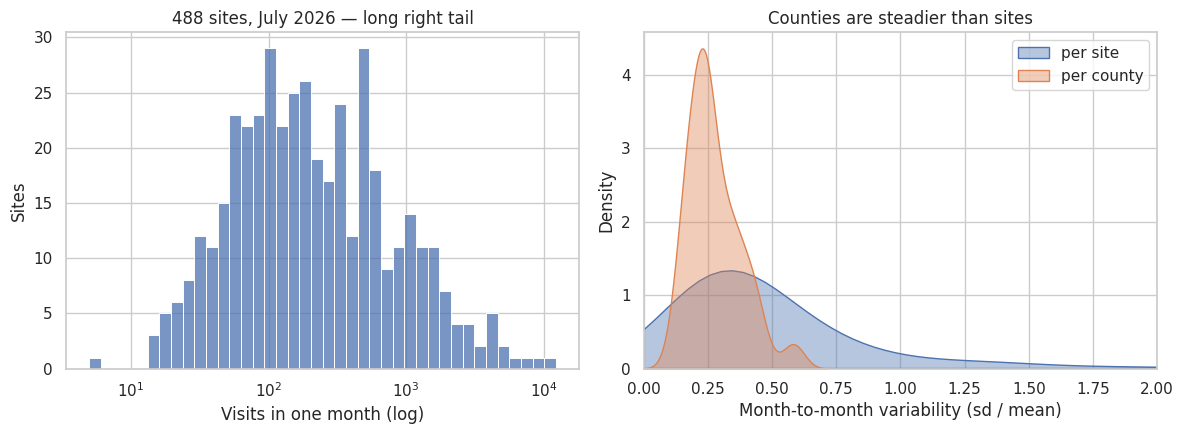

In [21]:
s26 = site[site.ym == pd.Period('2026-07','M')]
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
sns.histplot(s26.HouseholdsReg.replace(0,np.nan).dropna(), bins=40,
             log_scale=True, ax=axes[0])
axes[0].set(xlabel='Visits in one month (log)', ylabel='Sites',
            title=f'{len(s26)} sites, July 2026 — long right tail')

cv = (site.groupby('_id_site').HouseholdsReg.std() /
      site.groupby('_id_site').HouseholdsReg.mean()).dropna()
cvc = (panel.groupby('county').HouseholdsReg.std() /
       panel.groupby('county').HouseholdsReg.mean()).dropna()
sns.kdeplot(cv, ax=axes[1], label='per site', fill=True, alpha=.4)
sns.kdeplot(cvc, ax=axes[1], label='per county', fill=True, alpha=.4)
axes[1].set(xlim=(0,2), xlabel='Month-to-month variability (sd / mean)',
            title='Counties are steadier than sites'); axes[1].legend()
plt.tight_layout()

In [23]:
import plotly.express as px, json
from urllib.request import urlopen

mmg = pd.read_excel(D + 'MMG2026_Data_To_Share/MMG2026_2024_Data_To_Share.xlsx',
                    sheet_name='County')
mmg.columns = [str(c).strip() for c in mmg.columns]
mmg['fips5'] = mmg.FIPS.astype(str).str.zfill(5)
mmg = mmg[mmg.fips5.str[:2] == '27']
mmg['county'] = (mmg['County, State'].str.replace(' County, Minnesota','',regex=False)
                   .replace({'Lake of the Woods':'Lake Of The Woods'}))
fips = mmg.set_index('county').fips5

mp = out.copy()
mp['fips'] = mp.County.map(fips)
print('unmapped:', mp[mp.fips.isna()].County.tolist())    # should be []

with urlopen('https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json') as f:
    geo = json.load(f)

fig = px.choropleth(mp, geojson=geo, locations='fips', color='Visits',
                    color_continuous_scale='Viridis', scope='usa',
                    hover_name='County',
                    hover_data={'Visits':':,.0f','Pounds':':,.0f','fips':False},
                    title='Predicted August 2026 household visits by county')
fig.update_geos(fitbounds='locations', visible=False)
fig.show()


Output hidden; open in https://colab.research.google.com to view.